Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3438 - loss: 1.5348 - val_accuracy: 0.2917 - val_loss: 1.3863
Epoch 2/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3438 - loss: 1.3951 - val_accuracy: 0.2917 - val_loss: 1.3061
Epoch 3/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3438 - loss: 1.2780 - val_accuracy: 0.2917 - val_loss: 1.2374
Epoch 4/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3438 - loss: 1.1826 - val_accuracy: 0.2917 - val_loss: 1.1741
Epoch 5/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3229 - loss: 1.0931 - val_accuracy: 0.2917 - val_loss: 1.1202
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.2667 - loss: 1.0791
Test Accuracy: 0.2666666805744171


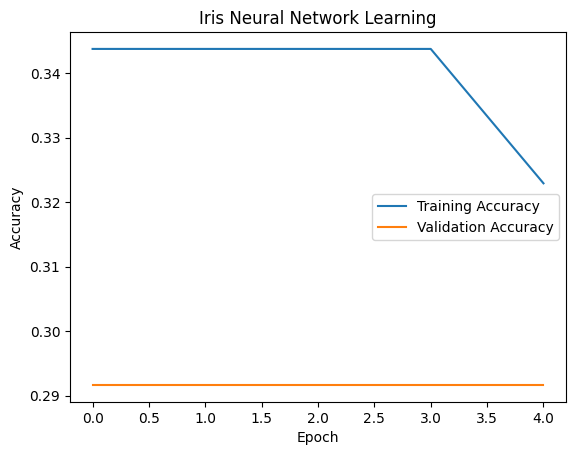

In [1]:

import tensorflow as tf
import matplotlib.pyplot as plt
import datetime
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import TensorBoard

iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Sequential([
    Input(shape=(4,)),
    Dense(10, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard = TensorBoard(log_dir=log_dir)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=8,
    validation_split=0.2,
    callbacks=[tensorboard],
    verbose=1
)

loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

tf.keras.utils.plot_model(
    model,
    to_file="iris_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Iris Neural Network Learning")
plt.legend()
plt.savefig("iris_accuracy.png")
plt.show()